# 04 Model evaluation

This notebook **only reads saved result tables**; it never refits a model and never opens the test data files. Test-set results come from `python -m scripts.evaluate_test`, which was run once after model selection was fixed (see `reports/test_evaluation_marker.json`).

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
from src.utils.config import ROOT
rep = ROOT / "reports"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
print(json.dumps(json.loads((rep / "test_evaluation_marker.json").read_text()), indent=1))

{
 "evaluated_at": "2026-10-19T18:00:46+00:00",
 "selected_frequency": "lightgbm_poisson",
 "selected_severity": "ridge_gamma_glm",
 "test_policies": 135599,
 "test_claims": 5306
}


## Validation (model selection) vs held-out test

In [2]:
val = pd.read_csv(rep / "frequency_model_comparison.csv").query("split == 'validation'").set_index("model")
test = pd.read_csv(rep / "test_results.csv")
tf = test[test.target == "frequency"].set_index("model")
print("Frequency, validation:"); display(val[["poisson_deviance", "mae_counts", "actual_to_predicted", "gini"]].round(4))
print("Frequency, held-out test:"); display(tf[["poisson_deviance", "mae_counts", "actual_to_predicted", "gini", "selected_dev_diff_vs_this", "ci_low", "ci_high"]].round(4))

Frequency, validation:


,poisson_deviance,mae_counts,actual_to_predicted,gini
model,,,,
constant_rate,0.2524,0.0741,0.9940,-0.0033
poisson_glm,0.2395,0.0725,0.9954,0.3027
negbin_glm,0.2396,0.0727,0.9904,0.3031
lightgbm_poisson,0.2338,0.0717,0.9972,0.3392


Frequency, held-out test:


,poisson_deviance,mae_counts,actual_to_predicted,gini,selected_dev_diff_vs_this,ci_low,ci_high
model,,,,,,,
constant_rate,0.2529,0.0743,1.0032,0.0022,-0.0155,-0.0172,-0.014
poisson_glm,0.2412,0.0729,1.0029,0.2884,-0.0038,-0.0049,-0.003
lightgbm_poisson (selected),0.2374,0.0723,1.0044,0.3213,NaN,NaN,NaN


**Reading this:** the selected model (LightGBM) is reliably better than the GLM and the flat rate on held-out data (the deviance-difference interval excludes 0). Its test Gini is a little below the validation Gini, the usual optimism from selecting on validation.

In [3]:
ts = test[test.target == "severity"].set_index("model")
display(ts[["gamma_deviance", "mae", "rmse", "actual_mean", "predicted_mean", "selected_dev_diff_vs_this", "ci_low", "ci_high"]].round(3))

,gamma_deviance,mae,rmse,actual_mean,predicted_mean,selected_dev_diff_vs_this,ci_low,ci_high
model,,,,,,,,
ridge_gamma_glm (selected),1.435,1933.047,6784.748,1870.621,2304.953,-0.033,-0.048,-0.015
constant_mean,1.468,2034.064,6796.428,1870.621,2438.255,NaN,NaN,NaN


**Caution:** the selected severity model beats the constant mean on test, but its predicted mean is lower than the constant's and closer to the test mean, so part of the gain is a lower overall *level*, not demonstrated ranking skill.

## Expected cost by risk segment (test), with 95% bootstrap intervals

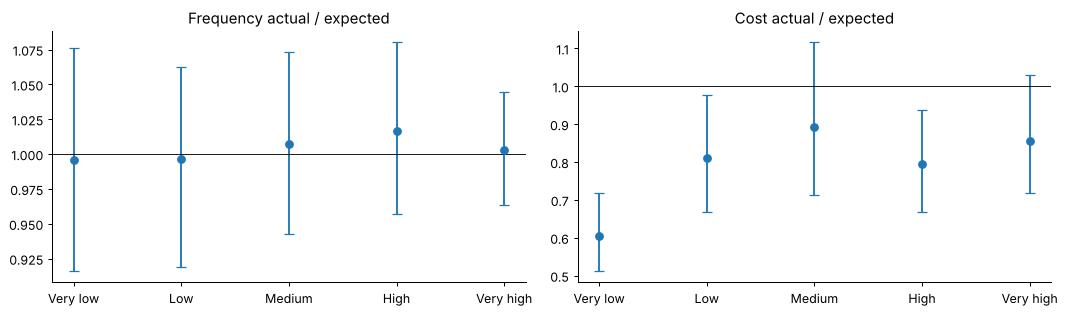

,segment,policies,freq_ae,freq_ci_low,freq_ci_high,cost_ae,cost_ci_low,cost_ci_high,actual_pure_premium,expected_pure_premium
0,ALL,135599,1.004,0.977,1.033,0.813,0.734,0.900,138.561,170.346
1,Very low,27281,0.996,0.916,1.076,0.605,0.513,0.718,50.722,83.905
2,Low,26819,0.996,0.919,1.063,0.811,0.668,0.977,90.177,111.126
3,Medium,27021,1.007,0.943,1.073,0.893,0.713,1.116,120.225,134.622
4,High,27398,1.016,0.957,1.080,0.795,0.669,0.937,142.613,179.409
5,Very high,27080,1.003,0.963,1.045,0.855,0.718,1.029,341.459,399.143


In [4]:
seg = pd.read_csv(rep / "test_segment_performance.csv")
order = ["Very low", "Low", "Medium", "High", "Very high"]
s = seg[seg.segment.isin(order)].set_index("segment").loc[order]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, kind, title in ((ax[0], "freq", "Frequency actual / expected"), (ax[1], "cost", "Cost actual / expected")):
    a.errorbar(range(len(s)), s[f"{kind}_ae"], yerr=[s[f"{kind}_ae"] - s[f"{kind}_ci_low"], s[f"{kind}_ci_high"] - s[f"{kind}_ae"]], fmt="o", capsize=4)
    a.axhline(1, color="k", lw=0.7); a.set_xticks(range(len(s))); a.set_xticklabels(order); a.set_title(title)
plt.tight_layout(); plt.show()
seg.round(3)

**Reading this:** frequency is well calibrated in every segment (intervals include 1.0). Cost actual/expected sits below 1.0 in every segment, with several intervals excluding 1.0: the model's *absolute* expected cost is too high on this test set, driven by the severity level (which one ~4.1M training claim inflates). **Use the model to rank and compare risks; do not use its absolute cost level for pricing without fixing the severity level.**

## Segment uncertainty on validation
Bootstrap intervals show that most segment-level cost deviations are consistent with noise:

In [5]:
pd.read_csv(rep / "segment_ae_uncertainty_validation.csv").round(3)

,segment,policies,freq_ae,freq_ci_low,freq_ci_high,freq_contains_one,cost_ae,cost_ci_low,cost_ci_high,cost_contains_one
0,ALL,135598,0.997,0.969,1.024,True,0.925,0.793,1.080,True
1,Very low,27087,1.012,0.940,1.091,True,1.210,0.683,1.950,True
2,Low,27200,0.936,0.873,1.004,True,0.640,0.518,0.807,False
3,Medium,27165,0.969,0.906,1.034,True,0.966,0.646,1.452,True
4,High,27095,0.967,0.908,1.028,True,0.929,0.678,1.262,True
5,Very high,27051,1.044,1.001,1.094,False,0.921,0.770,1.085,True


## Model complexity and interpretability trade-off
| Model | Complexity | Interpretability | Held-out evidence |
|---|---|---|---|
| Poisson GLM | low | coefficients and relativities | solid baseline |
| LightGBM Poisson | medium | SHAP, partial dependence | reliably better deviance and ranking |
| Ridge Gamma GLM | low | coefficients | beats a constant on test; weak evidence of ranking skill |
| Tweedie LightGBM (direct pure premium) | medium | SHAP | worse than frequency x severity on validation |